# Memory experiments: gross code and surface code

Three memory experiments, no logical operations yet:

| # | Circuit | Setup | Decoder |
|---|---|---|---|
| 1 | IBM's gross code circuit (Relay-BP repo) | [[144,12,12]], 288 qubits, 12 rounds, uniform circuit noise, p = 0.004 and 0.005 | BP-OSD (IBM's settings) |
| 2 | stabilizer-qec's gross code circuit | same setup, to cross-check IBM's | BP-OSD (same) |
| 3 | Surface code (Stim's rotated memory circuit) | d = 3 to 12, d rounds each | PyMatching |

For each one: the circuit, then the results. Figures are saved as PNG files in `figures/`. The full runs took
hours, so their numbers are loaded from `data/`; a short live run is included for each circuit to show the
pipeline working.

**Sources:** Bravyi et al., *Nature* 627, 778 (2024), arXiv:2308.07915 (gross code, syndrome circuit, noise
model) · IBM Relay-BP repo https://github.com/trmue/relay · stabilizer-qec 2.1.0 (PyPI) · Stim (Gidney,
*Quantum* 5, 497, 2021) · PyMatching (Higgott & Gidney, arXiv:2303.15933) · BP-OSD (Roffe et al., *PRR* 2,
043423, 2020; `ldpc` package).

## Setup

Run once in a fresh environment (Python 3.12 recommended). The versions are the ones the results were produced with.

In [1]:
%pip install -q stim==1.16.0 sinter==1.15.0 pymatching==2.4.0 ldpc==2.4.1 beliefmatching==0.2.0 stabilizer-qec==2.1.0 "numpy>=2.0,<2.3" scipy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


### Code and data used from this folder

Functions that several notebooks share are kept in `helpers/` rather than repeated in every notebook; they are
imported from there below. Each file is commented and can be read on its own.

| File | What it is for | Used here |
|---|---|---|
| `helpers/tour_helpers.py` | plotting, tables, running and caching experiments | `gate_counts`, `load_surface_results`, `plot_gate_counts`, `savefig`, `show_head`, `wilson` |
| `helpers/circuits.py` | loads or builds each gross / surface code circuit | `ibm_gross_memory_z`, `sq_gross_memory_z`, `surface_memory_z` |
| `helpers/ibm_filter.py` | IBM's Z-detector filter (from IBM's repo, Apache-2.0) | `ibm_filtered_z` |
| `helpers/decode_bposd.py` | BP-OSD decoding with IBM's settings (ldpc) | `logical_error_rate` |

Folders read or written:
- `data/`: saved results and IBM's circuits
- `figures/`: PNG files written by this notebook
- `cache/`: IBM-filtered circuits, written on first use

In [2]:
import sys, time
from pathlib import Path
sys.path.insert(0, "helpers")           # helper functions (see "Code and data used" above)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, stim
import tour_helpers as tour

ROOT = Path("data")                     # saved results of the full runs
from circuits import ibm_gross_memory_z, sq_gross_memory_z, surface_memory_z   # how each circuit is made
from ibm_filter import ibm_filtered_z                                          # IBM's Z-detector filter
from decode_bposd import logical_error_rate                                    # BP-OSD, IBM's settings

## 1 · IBM's gross code circuit

IBM ships one Stim file per noise level. We copied the gross code Z-memory files into `data/ibm_circuits/`.
The file starts by resetting all 288 qubits, each reset followed by its reset error (`R 72`, `X_ERROR(0.004) 72`, ...).
Below are the first lines after that: the first CX gates of round 1, each followed by its two-qubit noise.

In [3]:
P = 0.004
ibm = ibm_gross_memory_z(P)          # reads data/ibm_circuits/gross_memory_Z_p0.004.stim
tour.show_head(ibm, 12, start="CX")

... (lines 1-576 skipped)
CX 72 234
DEPOLARIZE2(0.004) 72 234
CX 73 235
DEPOLARIZE2(0.004) 73 235
CX 74 236
DEPOLARIZE2(0.004) 74 236
CX 75 237
DEPOLARIZE2(0.004) 75 237
CX 76 238
DEPOLARIZE2(0.004) 76 238
CX 77 239
DEPOLARIZE2(0.004) 77 239
... (26411 lines in total)


In [4]:
print(f"qubits: {ibm.num_qubits}   detectors: {ibm.num_detectors}   logical observables: {ibm.num_observables}")
tour.gate_counts(ibm).to_frame("count")

qubits: 288   detectors: 1728   logical observables: 12


,count
DEPOLARIZE2,10368
CX,10368
DEPOLARIZE1,3312
DETECTOR,1728
M,1008
R,1008
X_ERROR,1008
RX,864
Z_ERROR,864
MX,864


**Reading the counts.** 10,368 CX gates = 144 checks × 6 CX each × 12 rounds. Every CX is followed by a
`DEPOLARIZE2` (two-qubit noise), every reset by an `X_ERROR` or `Z_ERROR`. The 1,728 detectors are
144 checks × 12 rounds; IBM's filter keeps the Z-type ones before decoding (936).

In [5]:
ibm_z = ibm_filtered_z(ibm, f"ibm_p{P}")     # cached in cache/ after the first time
print("detectors before filter:", ibm.num_detectors, "  after (Z only):", ibm_z.num_detectors)

detectors before filter: 1728   after (Z only): 936


## 2 · stabilizer-qec's gross code circuit

Generated by the `stabilizer-qec` package (installed with pip, no repo needed) from the code's definition:
`BivariateBicycleCode("gross").memory_circuit(12, p)`. It produces only the Z-type detectors, so no filter is
needed.

In [6]:
sq = sq_gross_memory_z(P)
tour.show_head(sq, 6)                  # starts with qubit coordinates (where each qubit sits)
tour.show_head(sq, 10, start="CX")     # the first CX gates
print(f"\nqubits: {sq.num_qubits}   detectors: {sq.num_detectors}   logical observables: {sq.num_observables}")

QUBIT_COORDS(0, 0) 0
QUBIT_COORDS(1, 0) 72
QUBIT_COORDS(0, 1) 144
QUBIT_COORDS(1, 1) 216
QUBIT_COORDS(0, 2) 1
QUBIT_COORDS(1, 2) 73
... (1639 lines in total)
... (lines 1-295 skipped)
CX 198 216 199 217 200 218 201 219 202 220 203 221 204 222 205 223 206 224 207 225 208 226 209 227 210 228 211 229 212 230 213 231 214 232 2 ...
DEPOLARIZE2(0.004) 198 216 199 217 200 218 201 219 202 220 203 221 204 222 205 223 206 224 207 225 208 226 209 227 210 228 211 229 212 230 2 ...
DEPOLARIZE1(0.004) 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 101 102 103 104 105 106 107 108 1 ...
TICK
CX 0 73 1 74 2 75 3 76 4 77 5 72 6 79 7 80 8 81 9 82 10 83 11 78 12 85 13 86 14 87 15 88 16 89 17 84 18 91 19 92 20 93 21 94 22 95 23 90 24  ...
DEPOLARIZE2(0.004) 0 73 1 74 2 75 3 76 4 77 5 72 6 79 7 80 8 81 9 82 10 83 11 78 12 85 13 86 14 87 15 88 16 89 17 84 18 91 19 92 20 93 21 94 ...
TICK
CX 0 150 1 151 2 152 3 153 4 154 5 155 6 156 7 157 8 158 9 159 10 160 11 161 12 1

### The two circuits side by side

Same code, same noise model on paper. The chart compares how often each operation appears.

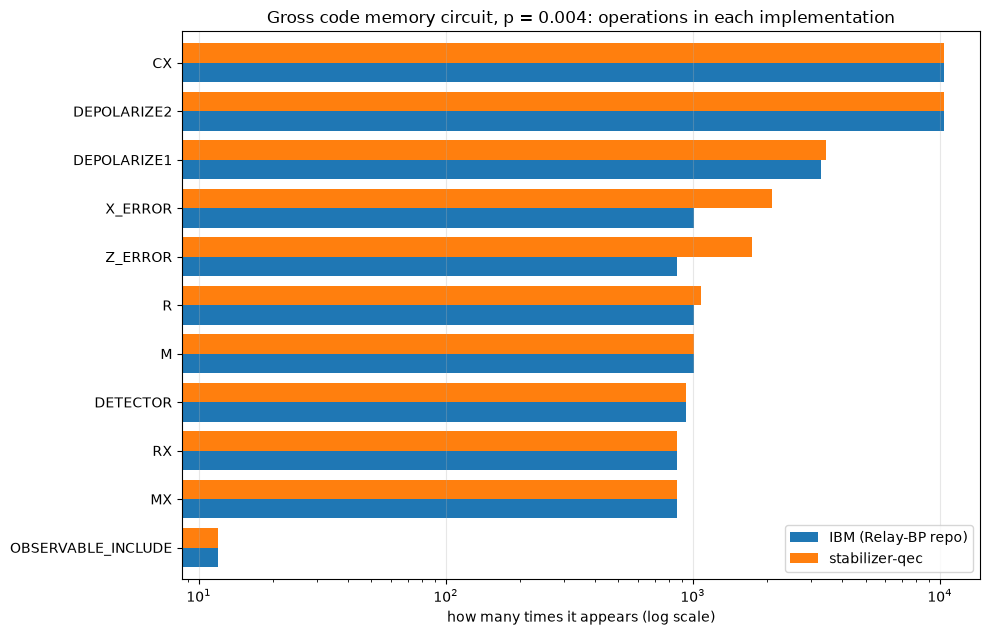

,IBM (Relay-BP repo),stabilizer-qec
OBSERVABLE_INCLUDE,12,12
MX,864,864
RX,864,864
DETECTOR,936,936
M,1008,1008
R,1008,1080
Z_ERROR,864,1728
X_ERROR,1008,2088
DEPOLARIZE1,3312,3456
DEPOLARIZE2,10368,10368


In [7]:
counts = tour.plot_gate_counts({"IBM (Relay-BP repo)": ibm_z, "stabilizer-qec": sq},
                               "Gross code memory circuit, p = 0.004: operations in each implementation",
                               save="gross_ibm_vs_sq_operations.png")
counts

**What the chart shows.** Both have the same 10,368 CX gates with their noise, the same measurements, the same
936 Z detectors and the same 12 logical observables. The visible differences:
- **X_ERROR / Z_ERROR about 2× higher in stabilizer-qec.** This is only how it is written: IBM puts the
  measurement error inside the measurement (`M(0.004)`), stabilizer-qec writes it as a separate `X_ERROR` /
  `Z_ERROR` just before a plain `M`. Same noise.
- **Real differences, small:** stabilizer-qec has 72 more resets (with their errors) and 3,456 idle-noise
  locations (`DEPOLARIZE1`) against IBM's 3,312. Slightly more noise, which fits its slightly higher failure
  rate at p = 0.005 below.

### Short live run (to show the pipeline)

Sample the circuit with Stim, decode every shot with BP-OSD (IBM's settings: min-sum, 80 iterations, OSD-CS
order 10), count shots where any of the 12 logical qubits came out wrong. 200 shots at p = 0.005 take about a
minute; the saved results below used 1,500–3,000 shots per point.

In [8]:
LIVE_P, LIVE_SHOTS = 0.005, 200
for name, circ in {"IBM": ibm_filtered_z(ibm_gross_memory_z(LIVE_P), f"ibm_p{LIVE_P}"),
                   "stabilizer-qec": sq_gross_memory_z(LIVE_P)}.items():
    n, f, s = logical_error_rate(circ, LIVE_SHOTS, workers=2)
    print(f"{name:15s} p = {LIVE_P}: {f}/{n} shots failed ({f/n:.1%}) in {s:.0f} s")

IBM             p = 0.005: 22/200 shots failed (11.0%) in 48 s
stabilizer-qec  p = 0.005: 23/200 shots failed (11.5%) in 50 s


### Saved results: both circuits against IBM's published numbers

From `data/results_gross.csv` . "IBM published" is
IBM's own BP-OSD result from the CSV in their repo. All three are the chance that **any** of the 12 logical
qubits fails over 12 rounds. Bars are 95% intervals.

,circuit,p,shots,failures,P_L_12rounds,ci_low,ci_high
0,ibm,0.005,1500,177,0.1180,0.1026,0.1353
1,sq,0.005,1500,217,0.1447,0.1278,0.1634
2,ibm,0.004,3000,80,0.0267,0.0215,0.0331
3,sq,0.004,3000,73,0.0243,0.0194,0.0305
4,ibm_published,0.004,10000,265,0.0265,0.0235,0.0298
5,ibm_published,0.005,5000,651,0.1302,0.1212,0.1398


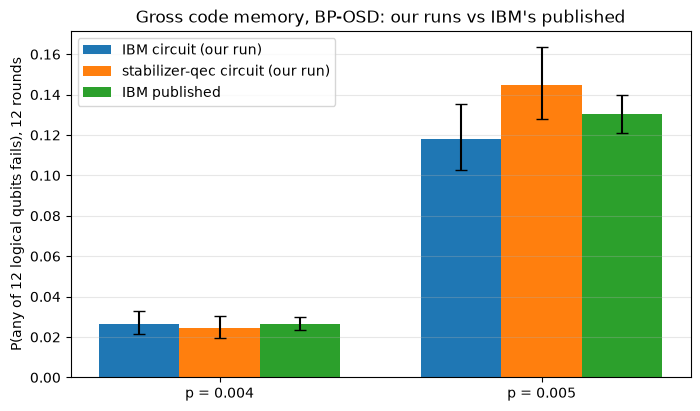

In [9]:
g = pd.read_csv(ROOT / "results_gross.csv")
display(g[["circuit", "p", "shots", "failures", "P_L_12rounds", "ci_low", "ci_high"]].round(4))

names = {"ibm": "IBM circuit (our run)", "sq": "stabilizer-qec circuit (our run)", "ibm_published": "IBM published"}
fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.25
for i, (key, label) in enumerate(names.items()):
    rows = g[g.circuit == key].sort_values("p")
    x = np.arange(len(rows)) + (i - 1) * width
    ax.bar(x, rows.P_L_12rounds, width, label=label)
    ax.errorbar(x, rows.P_L_12rounds, yerr=[rows.P_L_12rounds - rows.ci_low, rows.ci_high - rows.P_L_12rounds],
                fmt="none", color="black", capsize=4)
ax.set_xticks(range(2), [f"p = {p}" for p in sorted(g.p.unique())])
ax.set_ylabel("P(any of 12 logical qubits fails), 12 rounds")
ax.set_title("Gross code memory, BP-OSD: our runs vs IBM's published")
ax.legend(); ax.grid(axis="y", alpha=0.3)
tour.savefig("gross_results_bars.png"); plt.show()

**What it shows.**
- p = 0.004: all three agree (2.4–2.7%), the intervals overlap.
- p = 0.005: our run on IBM's circuit (11.8%) matches IBM's published 13.0%. The stabilizer-qec circuit fails
  a little more often (14.5%), consistent with its slightly larger number of noisy locations; all three
  intervals overlap, so more shots would be needed to call it a real difference.
- So: we reproduce IBM's published numbers on IBM's circuit, and stabilizer-qec's circuit gives the same
  answer at p = 0.004 and a similar one at p = 0.005.

## 3 · Surface code (Stim's rotated memory circuit)

Built by Stim itself: `stim.Circuit.generated("surface_code:rotated_memory_z", ...)` with every gate, reset,
measurement and idle step failing with probability p. Note this noise model is close to IBM's but **not
exactly the same** (for example, which idle steps get noise), so the gross vs surface comparison is
approximate. Here is d = 3, 3 rounds:

In [10]:
s3 = surface_memory_z(3, P)
tour.show_head(s3, 14, start="R")     # skip the qubit coordinates
print(f"\nqubits: {s3.num_qubits}   detectors: {s3.num_detectors}   logical observables: {s3.num_observables}")

... (lines 1-17 skipped)
R 1 3 5 8 10 12 15 17 19
X_ERROR(0.004) 1 3 5 8 10 12 15 17 19
R 2 9 11 13 14 16 18 25
X_ERROR(0.004) 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.004) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
DEPOLARIZE1(0.004) 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
DEPOLARIZE2(0.004) 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
DEPOLARIZE2(0.004) 2 1 16 15 11 10 8 14 3 9 12 18
... (89 lines in total)

qubits: 26   detectors: 24   logical observables: 1


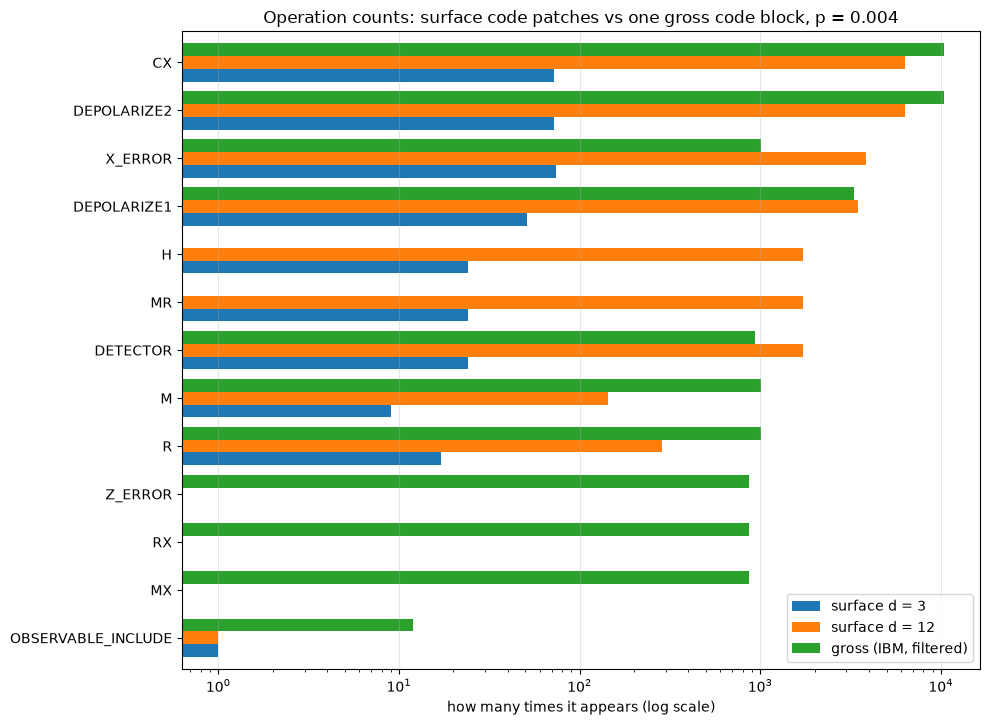

In [11]:
s12 = surface_memory_z(12, P)        # the project's comparison patch: d = 12, 12 rounds
tour.plot_gate_counts({"surface d = 3": s3, "surface d = 12": s12, "gross (IBM, filtered)": ibm_z},
                      "Operation counts: surface code patches vs one gross code block, p = 0.004",
                      save="surface_vs_gross_operations.png");

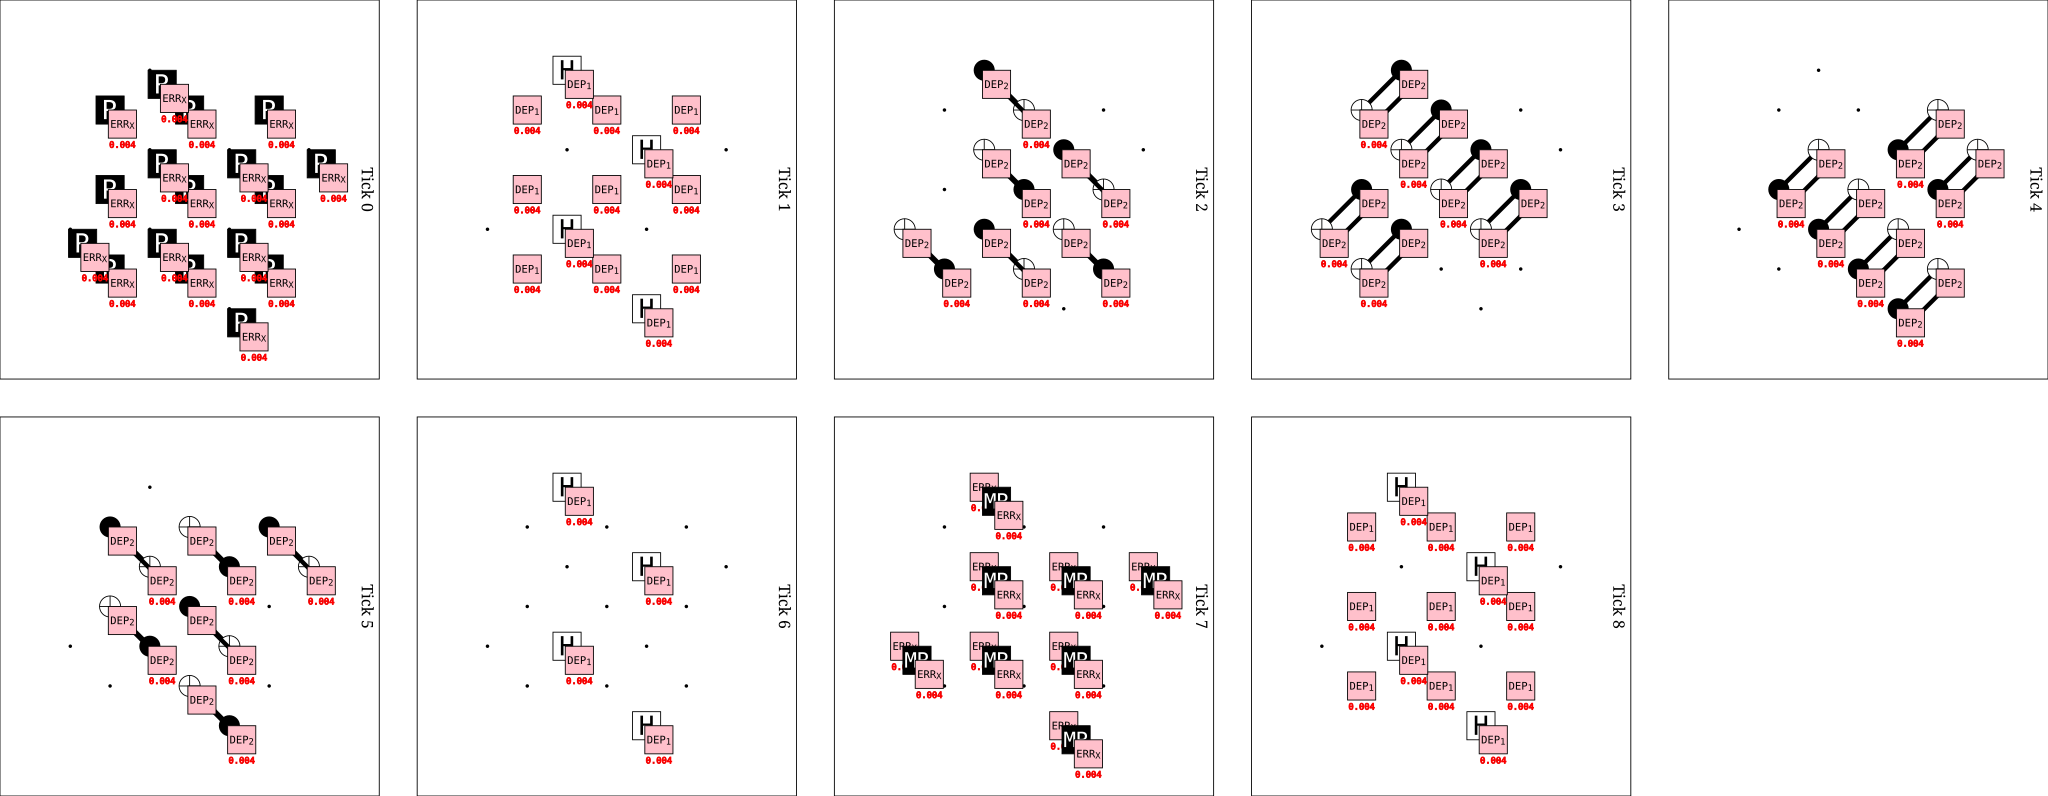

In [12]:
s3.diagram("timeslice-svg", tick=range(0, 9), rows=2)    # one round of the d = 3 circuit, gate by gate

### Short live run: d = 3, 5, 7 with PyMatching

In [13]:
import sinter
live = sinter.collect(num_workers=2, decoders=["pymatching"], max_shots=20_000, max_errors=100,
                      tasks=[sinter.Task(circuit=surface_memory_z(d, 0.005), json_metadata={"d": d})
                             for d in (3, 5, 7)])
for st in sorted(live, key=lambda s: s.json_metadata["d"]):
    print(f"d = {st.json_metadata['d']}, p = 0.005: {st.errors}/{st.shots} failed ({st.errors/st.shots:.2%})")

d = 3, p = 0.005: 101/6417 failed (1.57%)
d = 5, p = 0.005: 108/6417 failed (1.68%)
d = 7, p = 0.005: 154/15906 failed (0.97%)


### Saved results: d = 3, 5, 7, 9, 11, 12

From `data/results_surface.csv`: up to 200,000 shots or 200 failures per point.

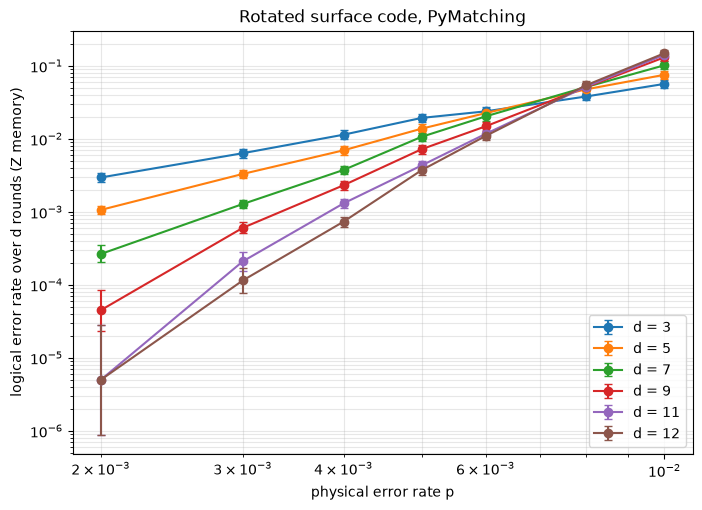

d,3,5,7,9,11,12
p,,,,,,
0.002,2.96e-03,1.06e-03,2.65e-04,4.50e-05,5.00e-06,5.00e-06
0.003,6.37e-03,3.31e-03,1.28e-03,6.05e-04,2.10e-04,1.15e-04
0.004,1.14e-02,6.98e-03,3.76e-03,2.32e-03,1.31e-03,7.35e-04
0.005,1.94e-02,1.38e-02,1.07e-02,7.23e-03,4.34e-03,3.74e-03
0.006,2.39e-02,2.26e-02,2.04e-02,1.49e-02,1.17e-02,1.10e-02
0.008,3.82e-02,4.78e-02,5.15e-02,5.13e-02,5.22e-02,5.45e-02
0.010,5.68e-02,7.56e-02,1.02e-01,1.31e-01,1.42e-01,1.49e-01


In [14]:
surf = tour.load_surface_results(ROOT / "results_surface.csv")
fig, ax = plt.subplots(figsize=(8, 5.5))
for d, rows in surf.groupby("d"):
    rows = rows[rows.failures > 0]
    ax.errorbar(rows.p, rows.P_L, yerr=[rows.P_L - rows.ci_low, rows.ci_high - rows.P_L],
                marker="o", capsize=3, label=f"d = {d}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("physical error rate p"); ax.set_ylabel("logical error rate over d rounds (Z memory)")
ax.set_title("Rotated surface code, PyMatching"); ax.grid(which="both", alpha=0.3); ax.legend()
tour.savefig("surface_threshold.png"); plt.show()
surf.pivot(index="p", columns="d", values="P_L").map(lambda v: f"{v:.2e}")

**What it shows.** Below about p ≈ 0.007 a bigger distance gives a lower error rate; above about 0.008 the
order flips. That crossing is the threshold for this circuit and noise model. At p = 0.002 a d = 3 patch fails
in about 0.3% of experiments, a d = 12 patch in about 1 in 200,000.

## 4 · One gross code block vs 12 surface code patches

Both store 12 logical qubits for 12 rounds. For the surface code we need 12 separate d = 12 patches; the
chance that any of them fails is 1 − (1 − P_patch)¹². Qubit cost: gross 288, surface 12 × (2·12² − 1) = 3,444.

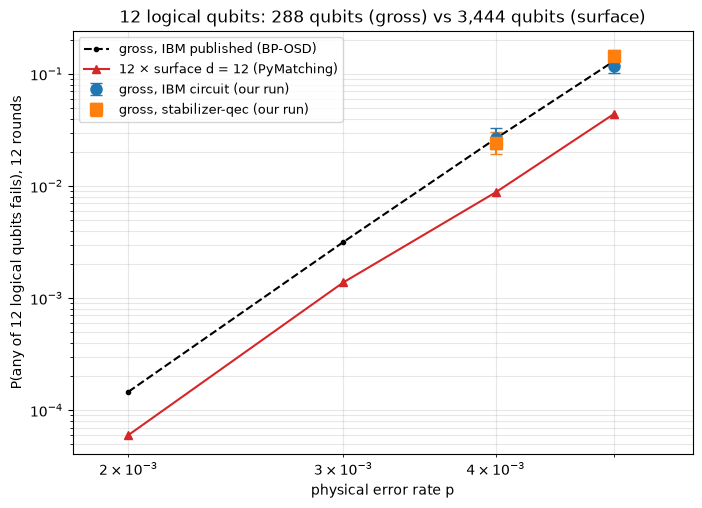

In [15]:
fig, ax = plt.subplots(figsize=(8, 5.5))
pub = g[g.circuit == "ibm_published"]
for key, label, mk in [("ibm", "gross, IBM circuit (our run)", "o"), ("sq", "gross, stabilizer-qec (our run)", "s")]:
    r = g[g.circuit == key]
    ax.errorbar(r.p, r.P_L_12rounds, yerr=[r.P_L_12rounds - r.ci_low, r.ci_high - r.P_L_12rounds],
                fmt=mk, capsize=4, markersize=8, label=label)
# IBM's full published sweep (p = 0.001 to 0.005) from their repo CSV
sweep = pd.DataFrame([(0.001, 10_000_000, 16), (0.002, 1_000_000, 146), (0.003, 100_000, 316),
                      (0.004, 10_000, 265), (0.005, 5_000, 651)], columns=["p", "shots", "failures"])
sweep = sweep[sweep.p >= 0.002]
ax.plot(sweep.p, sweep.failures / sweep.shots, "k--", marker=".", label="gross, IBM published (BP-OSD)")
s12r = surf[(surf.d == 12) & (surf.failures > 0) & (surf.p <= 0.005)]
ax.plot(s12r.p, 1 - (1 - s12r.P_L) ** 12, "-", color="tab:red", marker="^",
        label="12 × surface d = 12 (PyMatching)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.0018, 0.0058)   # the range where both codes were measured
ax.set_xlabel("physical error rate p"); ax.set_ylabel("P(any of 12 logical qubits fails), 12 rounds")
ax.set_title("12 logical qubits: 288 qubits (gross) vs 3,444 qubits (surface)")
ax.grid(which="both", alpha=0.3); ax.legend(fontsize=9)
tour.savefig("gross_vs_surface.png"); plt.show()

**What it shows.** From p = 0.002 to 0.005, twelve d = 12 surface code patches fail about 2–3× less often than
one gross code block, but they need 3,444 qubits against 288, about 12× more. That is the trade-off
Bravyi et al. report: similar protection for far fewer qubits. Caveats: the decoders differ (BP-OSD for the
gross code; IBM's Relay-BP would bring the gross curve down further), and the two noise models are close but
not exactly matched.

## 5 · Decoder speed test (from existing runs)

One gross code circuit, four decoders. The circuit is the logical-measurement circuit used in our test of IBM's
independence assumption (not part of this folder): 1 idle round, a 12-round measurement of a logical X, 1 idle round, at p = 0.004, on the 2-core cloud
machine. The numbers are from runs already done (24 Oct for `ldpc`, 7 Nov for the others); nothing is re-run here.

| Decoder | Package | Run |
|---|---|---|
| BP-OSD (our main decoder) | `ldpc` | 1,500 shots in 399 s (24 Oct) → 80 s per 300 shots |
| BP-OSD, same settings | stabilizer-qec | 300 shots |
| Ambiguity Clustering | stabilizer-qec | 300 shots |
| Relay-BP | stabilizer-qec (its own implementation of IBM's method) | 300 shots |

,decoder,shots,failures,seconds_per_300,P_fail
0,ldpc BP-OSD (our main decoder),1500,251,79.72,0.167
1,stabilizer-qec BP-OSD,300,53,26.00,0.177
2,stabilizer-qec Ambiguity Clustering,300,43,7.00,0.143
3,stabilizer-qec Relay-BP,300,40,192.00,0.133


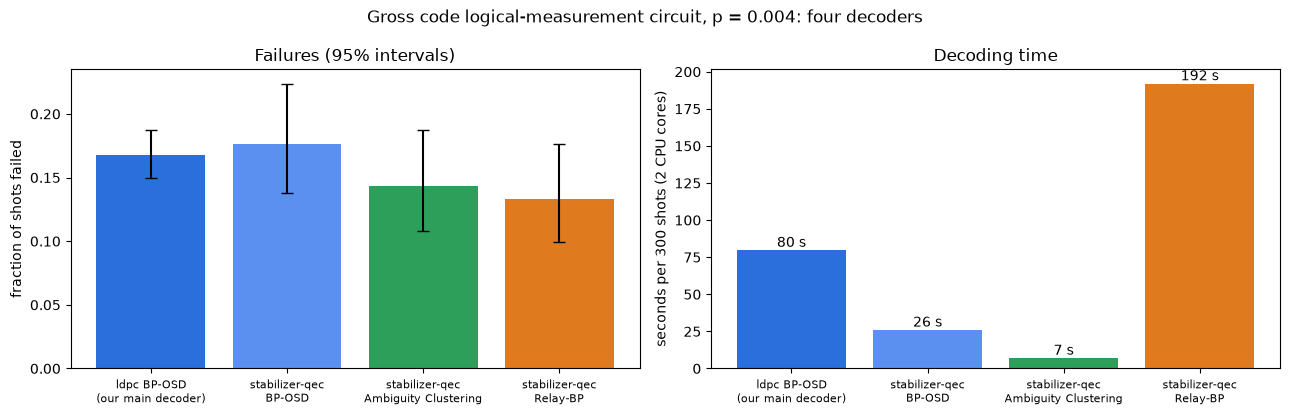

In [16]:
speed = pd.DataFrame([            # name, shots, failures, seconds per 300 shots  (existing runs)
    ("ldpc BP-OSD\n(our main decoder)", 1500, 251, 398.6 / 5),
    ("stabilizer-qec\nBP-OSD",             300,  53, 26),
    ("stabilizer-qec\nAmbiguity Clustering", 300, 43, 7),
    ("stabilizer-qec\nRelay-BP",           300,  40, 192),
], columns=["decoder", "shots", "failures", "seconds_per_300"])
speed["P_fail"] = speed.failures / speed.shots
ci = np.array([tour.wilson(f, n) for f, n in zip(speed.failures, speed.shots)])
display(speed.assign(decoder=speed.decoder.str.replace("\n", " ")).round(3))

cols = ["#2a6fdb", "#5b8ff0", "#2e9e5b", "#e07a1f"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.bar(speed.decoder, speed.P_fail, color=cols)
a1.errorbar(range(4), speed.P_fail, yerr=[speed.P_fail - ci[:, 0], ci[:, 1] - speed.P_fail], fmt="none", color="k", capsize=4)
a1.set_ylabel("fraction of shots failed"); a1.set_title("Failures (95% intervals)")
a2.bar(speed.decoder, speed.seconds_per_300, color=cols)
for i, s in enumerate(speed.seconds_per_300): a2.text(i, s, f"{s:.0f} s", ha="center", va="bottom")
a2.set_ylabel("seconds per 300 shots (2 CPU cores)"); a2.set_title("Decoding time")
for a in (a1, a2): a.tick_params(axis="x", labelsize=8)
fig.suptitle("Gross code logical-measurement circuit, p = 0.004: four decoders")
plt.tight_layout(); tour.savefig("decoder_speed_test.png"); plt.show()

**What it shows.** With these shot counts the four failure rates overlap within their error bars, so this
test does not say which decoder is more accurate. It does show speed on 2 cores: Ambiguity Clustering about
10× faster than our `ldpc` BP-OSD, stabilizer-qec's BP-OSD about 3× faster, and Relay-BP the slowest (it runs
many BP passes per shot; it is designed for parallel hardware, not a 2-core laptop).

## Figures

All saved in `figures/`:

In [17]:
for f in sorted(Path("figures").glob("*.png")):
    print(f.name)

bb_family_relay.png
decoder_speed_test.png
deltakit_decoders_surface.png
deltakit_gross_check_matrices.png
deltakit_gross_decoders.png
deltakit_noise_models.png
deltakit_surface_pymatching.png
deltakit_vs_ibm_gross_operations.png
detector_split.png
gross_ibm_vs_sq_operations.png
gross_results_bars.png
gross_vs_surface.png
ibm_published_decoders.png
sq_automorphisms.png
sq_four_decoders.png
sq_gross_check_matrices.png
sq_logical_supports.png
sq_logical_weights.png
sq_measurement_vs_memory.png
sq_memory_timeline.png
surface_threshold.png
surface_vs_gross_operations.png
